In [2]:
import joblib
import tensorflow as tf
import matplotlib.pyplot as plt

In [3]:
# load datasets
dts_train = tf.data.Dataset.load("../src/dts_train")
dts_test = tf.data.Dataset.load("../src/dts_test")
dts_val = tf.data.Dataset.load("../src/dts_val")

In [8]:
model = tf.keras.Sequential()
model.add(tf.keras.Input(shape=(150 , 150 , 3)))
model.add(tf.keras.layers.Conv2D(32, (3, 3), activation="relu"))
model.add(tf.keras.layers.MaxPooling2D((2 , 2)) )
model.add(tf.keras.layers.Conv2D(64, (3, 3), activation="relu"))
model.add(tf.keras.layers.MaxPooling2D((2 , 2)))
model.add(tf.keras.layers.Conv2D(128, (3, 3), activation="relu"))
model.add(tf.keras.layers.MaxPooling2D((2 , 2)))
model.add(tf.keras.layers.GlobalAveragePooling2D())
model.add(tf.keras.layers.Dense(128 , activation='relu'))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(6 , activation='softmax'))
model.compile(optimizer="adam" , loss="sparse_categorical_crossentropy" , metrics=['accuracy'])
early_stoping = tf.keras.callbacks.EarlyStopping(monitor='val_loss' , patience=3 , restore_best_weights=True)

In [11]:
history = model.fit(dts_train , validation_data=dts_val , epochs=30 , callbacks=[early_stoping])

Epoch 1/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 39s 91ms/step - accuracy: 0.7602 - loss: 0.6728 - val_accuracy: 0.7676 - val_loss: 0.6255
Epoch 2/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 40s 94ms/step - accuracy: 0.7687 - loss: 0.6440 - val_accuracy: 0.7870 - val_loss: 0.5793
Epoch 3/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 55s 129ms/step - accuracy: 0.7760 - loss: 0.6232 - val_accuracy: 0.7770 - val_loss: 0.5988
Epoch 4/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 56s 131ms/step - accuracy: 0.7803 - loss: 0.6144 - val_accuracy: 0.7975 - val_loss: 0.5728
Epoch 5/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 77s 181ms/step - accuracy: 0.7843 - loss: 0.5998 - val_accuracy: 0.7870 - val_loss: 0.5869
Epoch 6/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 75s 176ms/step - accuracy: 0.7928 - loss: 0.5834 - val_accuracy: 0.7987 - val_loss: 0.5574
Epoch 7/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 2589s 6s/step - accuracy: 0.7972 - loss: 0.5675 - val_accuracy: 0.8022 - val_loss: 0.5638
Epoch 8/30
426/426 ━━━━━━━━━━━━━━━━━━━━ 53s 125ms/step - accuracy: 0.8040 - loss: 0.54

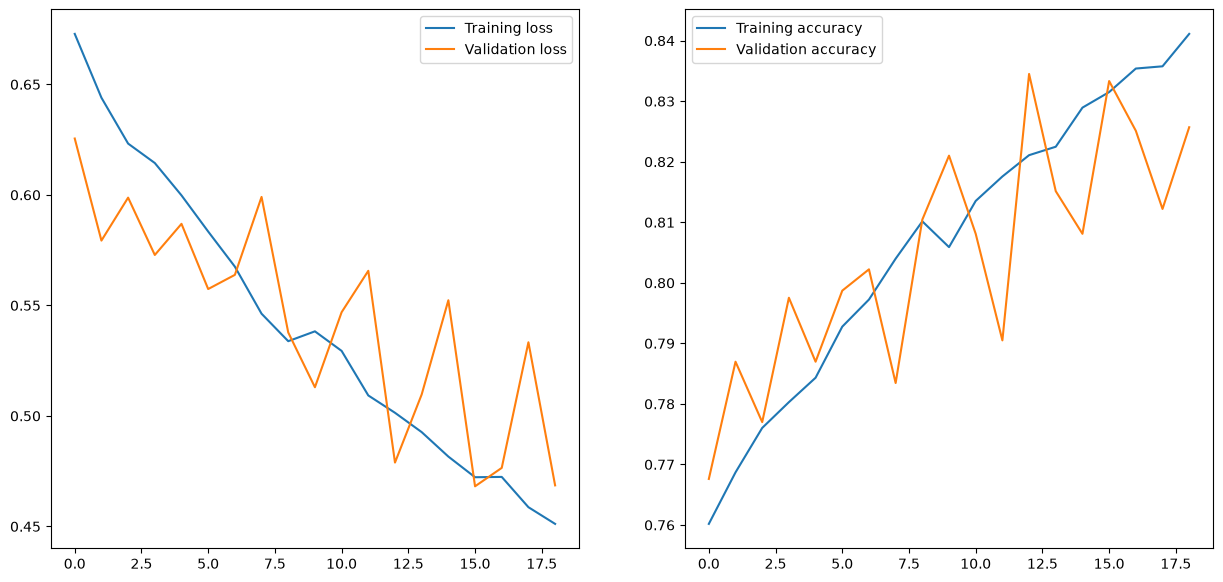

In [ ]:
fig ,axes =  plt.subplots(1 , 2 , figsize=(15 , 7))
axes[0].plot(history.history['loss'] , label="Training loss")
axes[0].plot(history.history['val_loss'] , label="Validation loss")
axes[0].legend()

axes[1].plot(history.history['accuracy'] , label="Training accuracy")
axes[1].plot(history.history['val_accuracy'] , label="Validation accuracy")
axes[1].legend()
plt.show()

In [13]:
print(history.history['val_accuracy'])
print(history.history['accuracy'])
print(history.history['loss'])
print(history.history['val_loss'])

[0.7676056623458862, 0.7869718074798584, 0.7769953012466431, 0.797535240650177, 0.7869718074798584, 0.7987089157104492, 0.8022300601005554, 0.783450722694397, 0.81044602394104, 0.8210093975067139, 0.8080986142158508, 0.7904929518699646, 0.8345070481300354, 0.8151408433914185, 0.8080986142158508, 0.8333333134651184, 0.8251173496246338, 0.8122065663337708, 0.8257042169570923]
[0.7601819634437561, 0.7686945199966431, 0.7760328650474548, 0.7802891135215759, 0.7843252420425415, 0.7927643656730652, 0.7972407937049866, 0.8039920926094055, 0.8101562857627869, 0.8059000372886658, 0.8135319352149963, 0.8175680637359619, 0.8210904598236084, 0.8224847912788391, 0.8289425373077393, 0.8315109610557556, 0.8354002833366394, 0.8357672095298767, 0.8411242365837097]
[0.6728423237800598, 0.643970787525177, 0.6232133507728577, 0.6144217252731323, 0.5997870564460754, 0.5834250450134277, 0.5675411820411682, 0.5462490916252136, 0.5338119864463806, 0.5382676124572754, 0.5294206142425537, 0.5092599391937256, 0.

In [14]:
model.save("../models/intel_cnn.keras")